# Supervised Learning & Model Engineering - Group project
# STEP 6: Final model, evaluated once on the test set

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (lead for this step: Eliott, reviewed by all)
**Course reference:** Session 5 ("CV tuning + test set": tune with CV, freeze the modelling choices, evaluate once on the untouched test set), Session 6 (threshold and business cost, rule of STEP 4), Sessions 1 and 6 (metrics, confusion matrix)
**Code:** `src/final.py`. Settings: `config.yaml`, section `final`. Results: `reports/final/`. Tests: `tests/test_final.py`.

### How to read this notebook
Same labels as the previous steps: **What we see**, **What we decide**, **What could invalidate it**, **Note for STEP X**, **Limitation**.

### The rule of this step
Until now, every number came from the development set (80%). The test set (20%, 9,758 people) was locked in STEP 1.
STEP 6 opens it **once**, to **measure**, never to **choose**:
1. **Freeze** (Part A): model, hyperparameters and threshold are read from the STEP 4 and 5 results, all computed on the development set.
2. **Refit** the frozen Pipeline on the whole development set (in cross-validation each model only saw 4/5 of it).
3. **Measure** on the test set (Parts B to E). Nothing is changed after this point.

### How to run
`python -m src.final` (about 1 minute) writes `reports/final/`. This notebook runs the same code and explains the results.

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config, load_splits, resolve
from src.final import load_best_params, oof_threshold, run_final, save_results, predict_decision

warnings.filterwarnings("ignore")
cfg = load_config()
FIG_DIR = cfg["paths"]["figures_dir"]
LABELS = {"lightgbm": "LightGBM (final)", "logistic": "Logistic regression (reference)",
          "lightgbm_amounts": "LightGBM + exact amounts (reference)"}
COLORS = {"lightgbm": "#fc8d62", "logistic": "#8da0cb", "lightgbm_amounts": "#cccccc"}
sns.set_theme(style="whitegrid")

def savefig(name: str) -> None:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")

/home/claude/venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---
# Part A - What is frozen before the test set is opened

In [2]:
# ===================== A. What is frozen BEFORE the test set is opened =====================
X_dev, _, y_dev, _ = load_splits(cfg)          # Part A only uses the development set
final, ref = cfg["final"]["model"], cfg["final"]["reference"]

print(f"Final model (config.yaml, decision 35): {final}")
print("Hyperparameters (Optuna, STEP 5):")
for k, v in load_best_params(cfg, final).items():
    print(f"   {k:18s} {v:.4g}" if isinstance(v, float) else f"   {k:18s} {v}")
for m in (final, ref):
    print(f"Threshold of {m:9s} (STEP 4 rule on its out-of-fold predictions): {oof_threshold(cfg, m, y_dev):.2f}")

Final model (config.yaml, decision 35): lightgbm
Hyperparameters (Optuna, STEP 5):
   n_estimators       350
   learning_rate      0.02399
   num_leaves         21
   min_child_samples  25
   reg_lambda         8.431
   subsample          0.5998
   colsample_bytree   0.6114
Threshold of lightgbm  (STEP 4 rule on its out-of-fold predictions): 0.15
Threshold of logistic  (STEP 4 rule on its out-of-fold predictions): 0.17


**What we see.** The final model is LightGBM with the 7 hyperparameters found by Optuna. Its threshold is **0.15**, the logistic regression's **0.17**: the same values as in STEP 5, recomputed here from the saved out-of-fold predictions. Nothing in this cell reads the test set.

**What we decide.**
1. **The final model is LightGBM, fixed now** (decision 39). The logistic regression is measured on the test set **for comparison only**. If we kept "the best of the two on the test set", the test set would become a selection tool and its score would be optimistic, the same problem that nested CV avoided in STEP 5.
2. **The threshold is part of the model** (decision 40). `predict_decision` returns "call" when P(>50K) >= 0.15. scikit-learn's `predict()` would use 0.5 and miss most of the wealthy prospects we want (Part C shows it).
3. **The frozen settings are written down** in `reports/final/final_model.yaml` (model, capital option, threshold, hyperparameters). STEPS 7 to 9 rebuild the same model from it.

---
# Part B - The single look at the test set

In [3]:
# ===================== B. The single look at the test set =====================
r = run_final(cfg)                 # refit on the 80% development set, then predict the 20% test set
save_results(cfg, r)
test = r["test"].set_index("model")
y_test = r["y_test"]
cols = ["threshold", "pr_auc", "roc_auc", "log_loss", "precision", "recall", "f1", "cost"]
display(test[cols].rename(index=LABELS).style.format(
    {"threshold": "{:.2f}", "pr_auc": "{:.3f}", "roc_auc": "{:.3f}", "log_loss": "{:.3f}",
     "precision": "{:.1%}", "recall": "{:.1%}", "f1": "{:.3f}", "cost": "{:,.0f}"}))
print(f"Test set: {len(y_test):,} people, {int(y_test.sum()):,} at >50K (prevalence {y_test.mean():.1%} = random PR-AUC)")

,threshold,pr_auc,roc_auc,log_loss,precision,recall,f1,cost
model,,,,,,,,
LightGBM (final),0.15,0.763,0.907,0.319,50.6%,91.7%,0.652,"3,060"
Logistic regression (reference),0.17,0.750,0.902,0.326,51.3%,90.5%,0.655,"3,114"
LightGBM + exact amounts (reference),0.18,0.832,0.929,0.278,56.1%,90.4%,0.692,"2,775"


Test set: 9,758 people, 2,336 at >50K (prevalence 23.9% = random PR-AUC)


**What we see.**
- **LightGBM (final): PR-AUC 0.763**, ROC-AUC 0.907, log-loss 0.319. The random baseline is 0.239 (the prevalence).
- Logistic regression: PR-AUC 0.750, ROC-AUC 0.902, log-loss 0.326. LightGBM is better on all three threshold-free metrics, as on the development set.
- At their thresholds, both find about 91% of the wealthy people (recall) with a precision of about 51%: one call in two reaches a >50K person.
- The "exact amounts" reference is far ahead (PR-AUC 0.832). Part E explains why we still do not use it.

**What we decide.** These are the numbers of the report. They are measured once and not changed.

---
# Part C - Business reading: what the bank gets

,people called,share called,wealthy found,wealthy missed,useless calls,cost (5 x missed + 1 x useless)
model,,,,,,
LightGBM (final),4238,43.4%,2143,193,2095,"3,060"
Logistic regression (reference),4124,42.3%,2115,221,2009,"3,114"


Calls with predict() (scikit-learn default, 0.5): 2,051


Calls with predict_decision(threshold = 0.15)     : 4,238


Figure saved: reports/figures/20_test_confusion_matrices.png


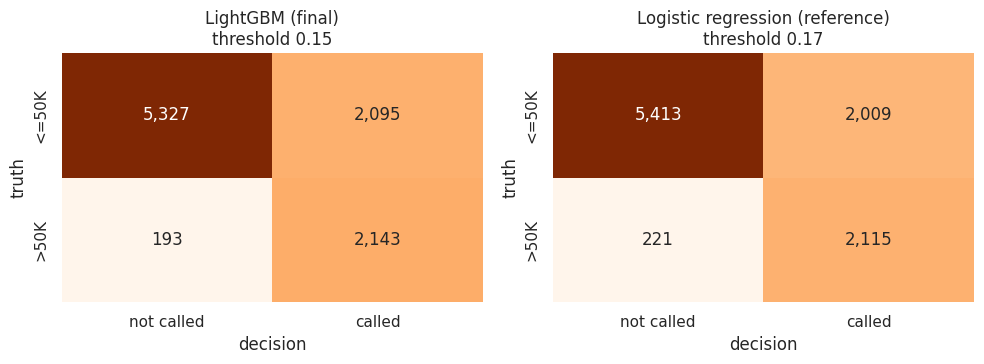

In [4]:
# ===================== C. Business reading: what the bank gets on the test set =====================
rows = []
for name in ["lightgbm", "logistic"]:
    t = test.loc[name]
    rows.append({"model": LABELS[name], "people called": int(t["calls"]), "share called": t["calls_share"],
                 "wealthy found": int(t["tp"]), "wealthy missed": int(t["fn"]),
                 "useless calls": int(t["fp"]), "cost (5 x missed + 1 x useless)": t["cost"]})
display(pd.DataFrame(rows).set_index("model").style.format(
    {"share called": "{:.1%}", "cost (5 x missed + 1 x useless)": "{:,.0f}"}))

# The delivered model applies the threshold: check on the final Pipeline
pipe = r["pipes"][final]
t_final = r["thresholds"][final]
print(f"Calls with predict() (scikit-learn default, 0.5): {int(pipe.predict(r['X_test']).sum()):,}")
print(f"Calls with predict_decision(threshold = {t_final:.2f})     : {int(predict_decision(pipe, r['X_test'], t_final).sum()):,}")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, name in zip(axes, ["lightgbm", "logistic"]):
    t = test.loc[name]
    cm = np.array([[t["tn"], t["fp"]], [t["fn"], t["tp"]]], dtype=int)
    sns.heatmap(cm, annot=True, fmt=",d", cbar=False, cmap="Oranges", ax=ax,
                xticklabels=["not called", "called"], yticklabels=["<=50K", ">50K"])
    ax.set_title(f"{LABELS[name]}\nthreshold {t['threshold']:.2f}"); ax.set_xlabel("decision"); ax.set_ylabel("truth")
savefig("20_test_confusion_matrices")
plt.show()

**What we see.**
- Among the 2,336 wealthy people of the test set, the final model **finds 2,143 (91.7%) and misses 193**. To do so it calls 4,238 people (43% of the list); 2,095 calls are useless.
- Compared with the logistic regression: **28 more wealthy people found** for 114 more calls. With the STEP 4 cost (a missed prospect = 5 calls), the cost goes from 3,114 to **3,060 (-1.7%)**, the same order as on the development set (-2.4%).
- With `predict()` at 0.5 the same model would call only 2,051 people (half as many): the threshold must be applied explicitly, as decided in A.2.

**What we decide.** LightGBM keeps a small but consistent advantage: better ranking (PR-AUC +0.013) and lower business cost. The gain is modest; the logistic regression remains a credible, more readable alternative, which we say plainly in the report.

**Limitation.** The cost ratio X = 5 is a business assumption (decision 27). STEP 4 showed that the remedy conclusion does not depend on it, but the exact threshold does.

---
# Part D - Was the cross-validation estimate honest?
If the development-set scores of STEP 5 were optimistic, the test score would be clearly lower. We compare the CV mean (5 folds) with the single test measure.

,cv_pr_auc_mean,cv_pr_auc_std,test_pr_auc,gap_in_std,cv_recall,test_recall
model,,,,,,
LightGBM (final),0.752,0.008,0.763,+1.2,91.6%,91.7%
Logistic regression (reference),0.745,0.012,0.750,+0.4,90.5%,90.5%


Figure saved: reports/figures/21_cv_vs_test.png


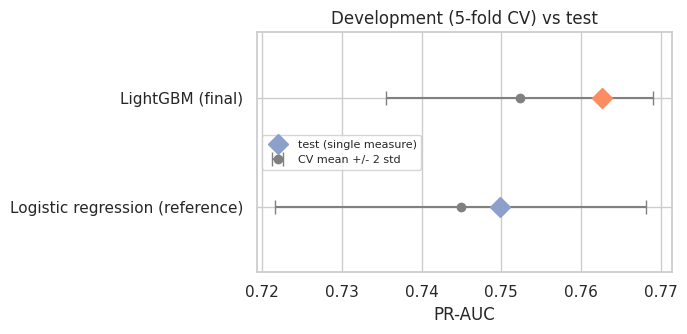

In [5]:
# ===================== D. Was the cross-validation estimate honest? =====================
dvt = r["dev_vs_test"]
display(dvt.rename(index=LABELS).style.format(
    {"cv_pr_auc_mean": "{:.3f}", "cv_pr_auc_std": "{:.3f}", "test_pr_auc": "{:.3f}",
     "gap_in_std": "{:+.1f}", "cv_recall": "{:.1%}", "test_recall": "{:.1%}"}))

fig, ax = plt.subplots(figsize=(7, 3.5))
for i, name in enumerate(["logistic", "lightgbm"]):
    m, s = dvt.loc[name, "cv_pr_auc_mean"], dvt.loc[name, "cv_pr_auc_std"]
    ax.errorbar(m, i, xerr=2 * s, fmt="o", color="grey", capsize=5, label="CV mean +/- 2 std" if i == 0 else None)
    ax.plot(dvt.loc[name, "test_pr_auc"], i, "D", color=COLORS[name], markersize=10,
            label="test (single measure)" if i == 0 else None)
ax.set_yticks([0, 1]); ax.set_yticklabels([LABELS["logistic"], LABELS["lightgbm"]])
ax.set_xlabel("PR-AUC"); ax.set_title("Development (5-fold CV) vs test"); ax.set_ylim(-0.6, 1.6); ax.legend(loc="center left", fontsize=8)
savefig("21_cv_vs_test")
plt.show()

**What we see.**
- LightGBM: CV 0.752 +/- 0.008, test **0.763**. Logistic regression: CV 0.745 +/- 0.012, test **0.750**.
- Both test values lie **inside the CV mean +/- 2 standard deviations**, slightly above. Recall is also stable (91.6% in CV, 91.7% on test).
- The ranking of the two models is the same on the development set and on the test set.

**What we decide.** The development-set estimates were **not optimistic**: no leakage in the Pipeline, and the tuning did not overfit the 5 folds (as the nested CV of STEP 5 already suggested). We report the test value as the final performance.

**Limitation.** The test set is one sample of 9,758 people. A test score slightly above the CV mean is normal variation, not a sign that the model is better than expected: the honest summary is "about 0.75-0.76".

---
# Part E - The cost of decision 7 (exact capital amounts)

The "amounts" reference uses the same LightGBM settings, but receives the exact `capital-gain` and `capital-loss` instead of the two 0/1 indicators. Its threshold (**0.18**) was chosen on its own out-of-fold predictions, like the others.

**What we see** (Part B table).
- PR-AUC **0.832** instead of 0.763 (+0.07), business cost **2,775** instead of 3,060 (-9%), precision 56% instead of 51% for the same recall.
- This confirms the STEP 1 check (+0.08 PR-AUC on the development set).

**What we decide.** We keep the indicators (decision 7 unchanged). The exact amounts are those of the **same year** as the income we predict, so a bank would not have them before the first contact, and some values act as codes (all-or-nothing outcomes). The +0.07 is the price of an honest model; we report it instead of hiding it.

**What could invalidate it.** If the bank received the previous year's tax return before contacting the prospect, the amounts (of the previous year) would become legitimate and this choice should be revisited.

---
# Part F - Decisions log for STEP 6 (copied into DECISIONS.md)

| # | Decision | Where |
|---|---|---|
| 39 | Final model frozen **before** the test set: LightGBM, Optuna hyperparameters of STEP 5. The logistic regression is a reference measured on test, never a fallback chosen on test | `config.yaml` (`final`), `src/final.py` |
| 40 | The threshold is part of the delivered model: call when P(>50K) >= 0.15 (STEP 4 rule on LightGBM's own out-of-fold predictions) | `predict_decision`, `reports/final/final_model.yaml` |
| 41 | Final Pipeline refitted on the whole development set, evaluated **once** on the test set | `run_final` |
| 42 | Test results: PR-AUC 0.763, ROC-AUC 0.907, log-loss 0.319; 91.7% of wealthy found, 43% of people called, cost 3,060 (logistic: 0.750, 3,114) | `reports/final/test_results.csv` |
| 43 | CV estimates were honest: test inside CV mean +/- 2 std for both models, same ranking | `reports/final/dev_vs_test.csv` |
| 44 | Cost of decision 7 on test: exact amounts would give PR-AUC 0.832 and cost 2,775 (-9%); indicators kept | Part E |

**Notes for the next steps.**
- **STEP 7 (calibration):** the reliability curve and the Brier score are computed on the test probabilities saved in `reports/final/test_predictions.csv` (column `lightgbm`), so the final model does not need to be refitted.
- **STEP 8 (SHAP):** rebuild the final model with `fit_on_development(cfg, "lightgbm", load_best_params(cfg, "lightgbm"), X_dev, y_dev)` and explain a few test predictions.
- **STEP 9 (fairness):** the test decisions are `test_predictions.csv["lightgbm"] >= 0.15`; `sex` and `race` are in `X_test` (same index).